In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
from scipy.stats import multivariate_normal
import os
import sys
from statistics import mean

import matplotlib

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

#max_angle = 1000000 * np.pi / 180

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']

#n_trajectories = 2
#x_data = x_data[:n_trajectories, :]
#y_data = y_data[:n_trajectories, :]

def resample_spline(mean, cov):
    mean_resampled = np.repeat(mean, 2)
    diag_cov = np.diag(cov)
    diag_cov = np.repeat(diag_cov, 2)
    cov_resampled = np.diag(diag_cov)
    return mean_resampled, cov_resampled

# Find proposal

In [2]:
def plot_torques(MEANS, COVS, n_knots=None, n_samples=10000, n_phis = 200, n_examples=0, torque_scale=50, plot_edges=True, use_Bsplines=False):

    TORQUE_FN = TORQUE_BSPLINE if use_Bsplines else TORQUE
    #plt.figure(figsize=(4, 4))

    #MEANS = [m[1:] for m in MEANS]
    #COVS = [c[1:,1:] for c in COVS]
    
    phi = np.linspace(-np.pi * 0.1, 2.1 * np.pi, n_phis)
    phi_draw = phi * 180 / np.pi

    use = -1
    sample_mean = np.mean(MEANS[use:], axis=0)
    sample_cov = np.mean(np.array(COVS[use:]), axis=0)

    TORQUES = []

    SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, n_samples)


    for s in SAMPLES:
        TORQUES.append(TORQUE_FN(phi, s))

    TORQUES = np.array(TORQUES)

    Tmax = torque_scale
    Tmin = -torque_scale

    bins = np.linspace(Tmin, Tmax, n_phis)

    extent = [phi_draw.min(), phi_draw.max(), Tmin, Tmax]
    def hist1d(x):
        hist = np.histogram(x, bins=bins, density=True)[0]
        return hist / hist.max()

    density = np.apply_along_axis(hist1d, axis=0, arr=TORQUES, )

    density_ = gaussian_filter(density, (0.0,0))
    #plt.figure(dpi=300)
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white","yellowgreen"])
    plt.imshow(density_, extent=extent, aspect='auto', origin='lower', cmap=cmap)

    torque_mean = np.mean(TORQUES, axis=0)
    torque_mode = bins[np.argmax(density_, axis=0)]
    torque_std = np.std(TORQUES, axis=0)

    torque_true = TORQUE(phi, ALPHAS)

    #if n_knots is not None:
    #    phi_knots = np.linspace(0, np.pi, n_knots+2)[1:-1]
    #    torque_knots = TORQUE(phi_knots, ALPHAS)
    #
    #    plt.scatter(phi_knots, torque_knots, c='r', s=10)
    #    #for phi_ in phi_knots:
    #    #    plt.axvline(phi_, color='k', alpha=0.5, lw=0.5, ls='--')

    
    for i in range(n_examples):

        SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, 1)

        TORQUES = []
        for s in SAMPLES:
            TORQUES.append(TORQUE_FN(phi, s))
        
        plt.plot(phi_draw, TORQUES[0], lw=1, alpha=1, ls='--', c='darkgreen')

    col='olivedrab'
    qtil = 2.575829
    
    plt.plot(phi_draw, torque_mean - qtil*torque_std, '-', lw=0.7, c=col)
    plt.plot(phi_draw, torque_mean + qtil*torque_std, '-', lw=0.7, c=col)
    #plt.plot(phi, torque_mode, '--', lw=0.7, alpha=1, c=col)
    #plt.plot(phi, torque_true, '-', lw=2, alpha=1, c='r')
    if plot_edges:
        plt.axvline(0, color='k', lw=2)
        plt.axvline(360, color='k', lw=2)
    plt.grid()
    plt.ylim(Tmin, Tmax)
    plt.xticks(np.arange(0, 360+1, 90))

    

In [3]:
def plot_cov_ellipse(mean, cov, color='b'):
    phi = np.linspace(0, 2*np.pi, 100)
    chol = np.linalg.cholesky(cov[:2, :2])
    ellipse = np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color)
    ellipse = 2*np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color, ls='--')

In [4]:
d0 = 0
d1 = 1

ndims = 2
centers = np.zeros(ndims)
count = 0

In [27]:
rng = np.random.default_rng()
def learn(x_data, y_data,
          progression=range(20),
          sample_count=1024 // 64,
          torque_scale=200,
          new_samples_only=True,
          max_angle = 90 * np.pi / 180,
          particle_count=100,
          use_Bsplines = False,
          clip_parameters=1000,
          mixing_ratio=0.8,
          search_size=1,
          smoothing_factor=1.0):
    global mean, cov, ALL_COORDS, ALL_TARGET_DENSITIES, ALL_LIKELIHOODS, count
    for prog in tqdm(progression):

        ''' GENERATE NEW TEST SAMPLES '''

        test_distribution = multivariate_normal(mean=mean, cov=search_size*cov, allow_singular=False)
        coords = test_distribution.rvs(sample_count)
        #print(coords.shape)
        likelihood = test_distribution.pdf(coords)

        props = 1 / likelihood
        props = props / np.sum(props)
        #coords = rng.choice(coords, size=sample_count, p=props)

        ''' EVALUATE POSTERIOR AT TEST POINTS '''

        logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                    PE, DT, DR, FORCE_STRENGTH,
                                    coords, torque_limit=max_angle,
                                    n_particles=particle_count,
                                    clip_params=clip_parameters,
                                    use_Bsplines=use_Bsplines,
                                    )
        logl = logl - np.max(logl)
        target_density = np.exp(logl)
        target_density = target_density / np.sum(target_density)

        # (Remnant of old testing code. More stable but incorrect.)
        #ALL_COORDS = np.concatenate((ALL_COORDS, coords))
        #ALL_TARGET_DENSITIES = np.concatenate((ALL_TARGET_DENSITIES, target_density))
        #ALL_LIKELIHOODS = np.concatenate((ALL_LIKELIHOODS, likelihood))
        #ALL_LIKELIHOODS = distribution.pdf(ALL_COORDS)
        # (Delete old data, otherwise the fit isn't correct -> Mitigating above issue.)

        ALL_COORDS = coords
        ALL_TARGET_DENSITIES = target_density
        ALL_LIKELIHOODS = likelihood

        ''' CALULATE NEW MEAN AND COVARIANCE'''
        mean_old = mean
        cov_old = cov
        mean = np.average(ALL_COORDS, axis=0, weights=ALL_TARGET_DENSITIES)
        cov = np.cov(ALL_COORDS.T, aweights=ALL_TARGET_DENSITIES)

        #cov /= smoothing_factor**2

        if np.any(np.isnan(cov)):
            cov = cov_old

        # (Stabilize the fit by mixing the old and new parameters)
        #mixing_ratio = mixing_ratio
        #mean = mixing_ratio * mean + (1 - mixing_ratio) * mean_old
        #cov = mixing_ratio * cov + (1 - mixing_ratio) * cov_old

        ''' STORE PROGRESS '''

        COVS.append(cov.copy())
        MEANS.append(mean.copy())

        plt.figure(dpi=120, figsize=(5, 5))

        ''' PLOT ORIGINAL LOG PARAMETERS '''

        plt.subplot(2, 2, 1)
        plt.gca().set_facecolor('silver')
        plt.gca().title.set_text("Log likelihood")
        #chan = np.exp(ALL_TARGET_DENSITIES/10)
        chan = target_density
        plt.hexbin((ALL_COORDS)[:, d0], (ALL_COORDS)[:, d1], C=chan, gridsize=32, reduce_C_function=np.max)
        plt.axvline(centers[0], color='r', linestyle='--', lw=1)
        plt.axhline(centers[1], color='r', linestyle='--', lw=1)
        plot_cov_ellipse(mean, cov, color='w')

        ''' PLOT ROTATED PARAMETERS '''

        eivals, eivecs = np.linalg.eig(cov)
        idx = np.argsort(np.abs(eivals))[::-1]
        eivals = eivals[idx]
        eivecs = eivecs[:, idx]
        def rotate(vec):
            return np.dot(vec, eivecs)
        
        def rotate_mat(mat):
            return np.dot(np.dot(eivecs.T, mat), eivecs)
        
        plt.subplot(2, 2, 2)
        plt.gca().set_facecolor('silver')
        #chan = np.exp(ALL_TARGET_DENSITIES/10)
        chan = target_density
        plt.hexbin(rotate(ALL_COORDS)[:, d0], rotate(ALL_COORDS)[:, d1], C=chan, gridsize=32)
        plot_cov_ellipse(rotate(mean), rotate_mat(cov), color='w')


        ''' PLOT CONVERGENCE '''

        plt.subplot(2, 2, 3)

        COVS_flat = [cov_.copy() for cov_ in COVS]
        for cov_ in COVS_flat:
            np.fill_diagonal(cov_, np.nan)
        COVS_flat = [cov_.flatten() for cov_ in COVS]

        COVS_flat = np.stack(COVS_flat, axis=0)
        plt.semilogy(np.abs(COVS_flat), 'red', label='Covariances')

        COVS_flat = [np.diagonal(cov) for cov in COVS]
        COVS_flat = np.stack(COVS_flat, axis=0)
        plt.semilogy(np.abs(COVS_flat), 'blue', label='Diagonals')
        plt.xlabel("Iteration")
        plt.ylabel("Covariance matrix element")

        ''' PLOT POSTERIOR TORQUE '''

        plt.subplot(2, 2, 4)
        plot_torques(MEANS, COVS, n_knots=ndims-1, torque_scale=torque_scale, use_Bsplines=use_Bsplines)
        plt.tight_layout()
        plt.savefig(f"img/proposal_convergence{count}.png", dpi=300)
        plt.xlim(0, 180)
        plt.xlabel(r"$\varphi-\theta$")
        plt.ylabel(r"$\tau\sigma$")
        plt.show()
        count += 1

# Learning

# Spectral 2D

  0%|                                                    | 0/10 [00:00<?, ?it/s]

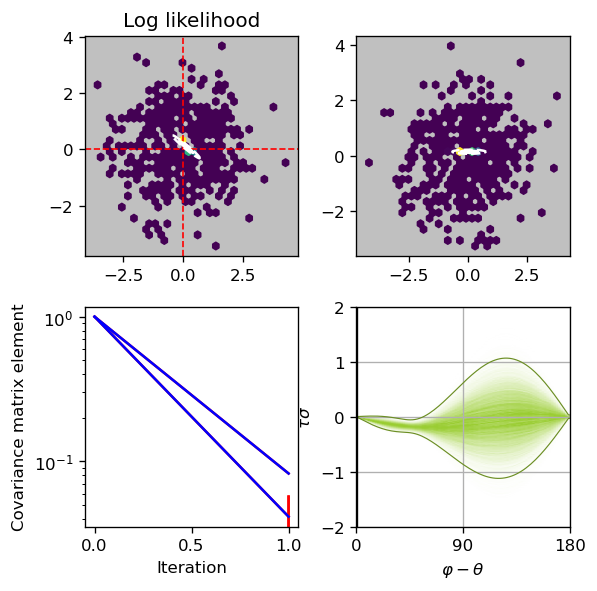

 10%|████▍                                       | 1/10 [00:24<03:44, 24.96s/it]


SystemError: CPUDispatcher(<function calc_logl_core at 0x120ae58a0>) returned a result with an exception set

In [32]:
# Set up base run

n_trajectories = 20
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

clipping = np.inf

search_size = 1.5
initial_radius = 1
ndims = 2
centers = np.zeros(ndims)
mean = centers.copy()
cov = np.eye(ndims) * initial_radius**2

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn(x_data,
      y_data,
      progression=range(10),
      sample_count=1024//2,
      particle_count=100,
      new_samples_only=True,
      torque_scale=2.0,
      clip_parameters=10,
      search_size=search_size,
      mixing_ratio=0.8,
      smoothing_factor=1.,
      max_angle = 1000 * np.pi / 180,
      use_Bsplines = False,
      )

mean_3 = mean.copy()
cov_3 = cov.copy()

np.save("mean_3.npy", mean_3)
np.save("cov_3.npy", cov_3)

# Try Dynesty

In [11]:
from dynesty import NestedSampler

In [55]:
def prior_transform(u):

    x = 2 * u - 1
    x *= 10.

    return x

def loglike(inn):

    progression=range(10),
    sample_count=1024//2,
    particle_count=100,
    new_samples_only=True,
    torque_scale=2.0,
    clip_parameters=1000000,
    search_size=10,
    mixing_ratio=0.8,
    smoothing_factor=1.,
    max_angle = 1000 * np.pi / 180,
    use_Bsplines = False,

    test_distribution = multivariate_normal(mean=mean, cov=cov, allow_singular=False)
    coords = test_distribution.rvs(sample_count)

    
    logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                PE, DT, DR, FORCE_STRENGTH,
                                coords, torque_limit=max_angle,
                                n_particles=particle_count,
                                clip_params=clip_parameters,
                                use_Bsplines=use_Bsplines,
                                )
    return logl

loglike(1)

TypingError: Failed in nopython mode pipeline (step: nopython frontend)
No implementation of function Function(<built-in function gt>) found for signature:
 
 >>> gt(float64, UniTuple(int64 x 1))
 
There are 22 candidate implementations:
   - Of which 18 did not match due to:
   Overload of function 'gt': File: <numerous>: Line N/A.
     With argument(s): '(float64, UniTuple(int64 x 1))':
    No match.
   - Of which 2 did not match due to:
   Operator Overload in function 'gt': File: unknown: Line unknown.
     With argument(s): '(float64, UniTuple(int64 x 1))':
    No match for registered cases:
     * (bool, bool) -> bool
     * (int8, int8) -> bool
     * (int16, int16) -> bool
     * (int32, int32) -> bool
     * (int64, int64) -> bool
     * (uint8, uint8) -> bool
     * (uint16, uint16) -> bool
     * (uint32, uint32) -> bool
     * (uint64, uint64) -> bool
     * (float32, float32) -> bool
     * (float64, float64) -> bool
   - Of which 2 did not match due to:
   Overload in fun

In [48]:
cov

array([[ 0.0825905806, -0.0571577796],
       [-0.0571577796,  0.0415539527]])